# Семинар 4. SASRec на Yambda

In [1]:
!pip install -q implicit huggingface_hub

In [2]:
import os, math, time, random, json, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
QUICK = os.environ.get('SEMINAR_QUICK') == '1'   # короткий прогон на CPU для проверки кода
print('device:', DEVICE, '| QUICK' if QUICK else '')

BLUE, PINK, CYAN, GRAY = '#0077FF', '#FF3885', '#7CEDF8', '#B8C2CC'
PALETTE = [BLUE, PINK, '#00B39F', '#FFA000', '#7B61FF', '#2DC4E0', '#E5484D', '#8A6D3B']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 11, 'axes.titleweight': 'bold'})

device: cuda 


In [3]:
PRETRAINED = True         # True: взять готовые модели из artifacts/, если они там есть; False: обучить и сохранить
ART_DIR = 'artifacts'

CFG = dict(
    catalog_size=50_000,     # сколько самых популярных треков оставляем в каталоге
    max_len=50,              # длина окна истории
    windows_per_user=8,      # сколько окон на пользователя берём за эпоху (не больше длины истории / max_len)
    batch_size=64,
    epochs=15,            # с каталогом 50k за 5 эпох CE ещё не дорастает; на T4 эпоха ≈ 1 мин
    d_model=64, n_heads=2, n_layers=2, dropout=0.2,
    lr=1e-3,
    n_neg=1,                 # число негативов на позицию для BCE
    eval_users_val=None,     # валидация после эпохи: None — все пользователи val, число — случайная подвыборка
)
if QUICK:
    CFG.update(catalog_size=5_000, max_len=50, windows_per_user=4, epochs=1, n_users=600, eval_users_val=300)
CFG

{'catalog_size': 50000,
 'max_len': 50,
 'windows_per_user': 8,
 'batch_size': 64,
 'epochs': 15,
 'd_model': 64,
 'n_heads': 2,
 'n_layers': 2,
 'dropout': 0.2,
 'lr': 0.001,
 'n_neg': 1,
 'eval_users_val': None}

## 1. Данные
Yambda-50M: `uid`, `item_id`, `timestamp`, `is_organic`, `played_ratio_pct`, `track_length_seconds`.

In [4]:
DATA_DIR = 'data'

def fetch(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        from huggingface_hub import hf_hub_download
        hf_hub_download('yandex/yambda', name, repo_type='dataset', local_dir=DATA_DIR)
    return path

listens = pd.read_parquet(fetch('flat/50m/listens.parquet'))
artist_of = (pd.read_parquet(fetch('artist_item_mapping.parquet'))   # трек -> артист, пригодится для картинок
             .drop_duplicates('item_id').set_index('item_id').artist_id)
if QUICK:
    keep = np.random.default_rng(SEED).choice(listens.uid.unique(), CFG['n_users'], replace=False)
    listens = listens[listens.uid.isin(keep)].reset_index(drop=True)
print(f'{len(listens):,} прослушиваний, {listens.uid.nunique():,} пользователей, {listens.item_id.nunique():,} треков')
print(f'период: {listens.timestamp.max() / 86400:.0f} дней')
listens.head()

flat/50m/listens.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

flat/50m/listens.parquet: downloading bytes:           |  0.00B            

artist_item_mapping.parquet: reconstructing file:   0%|          |  0.00B / 38.3MB            

artist_item_mapping.parquet: downloading bytes:           |  0.00B            

46,467,212 прослушиваний, 9,238 пользователей, 877,168 треков
период: 301 дней


,uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds
0,100,39420,8326270,0,100,170
1,100,39420,1441281,0,100,105
2,100,39625,286361,0,100,185
3,100,40110,732449,0,100,240
4,100,40360,3397170,0,46,130


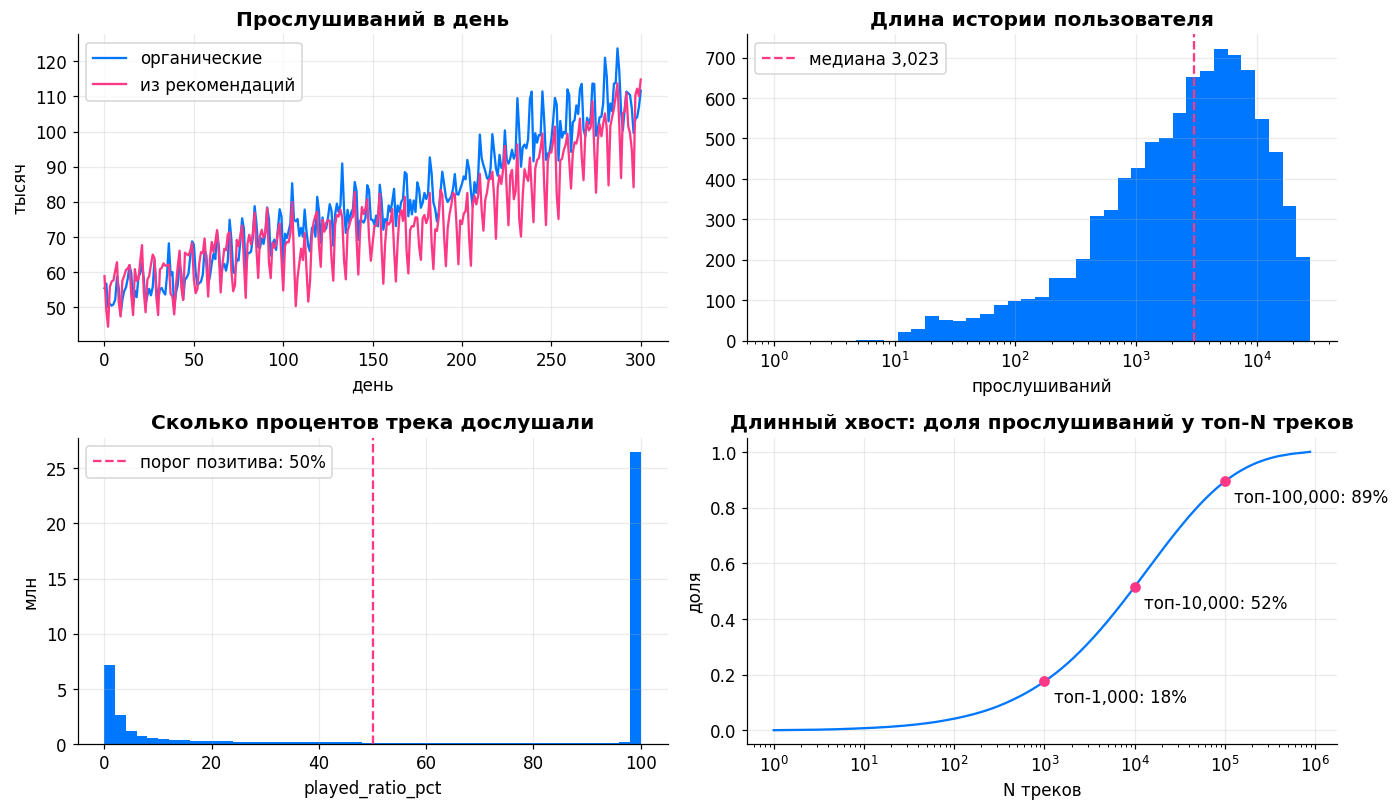

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))

# 1. Сколько слушают по дням: органика и рекомендации
day = listens.timestamp // 86_400
per_day = listens.groupby([day, 'is_organic']).size().unstack(fill_value=0)
ax = axes[0, 0]
ax.plot(per_day.index, per_day[1] / 1e3, color=BLUE, label='органические')
ax.plot(per_day.index, per_day[0] / 1e3, color=PINK, label='из рекомендаций')
ax.set(title='Прослушиваний в день', xlabel='день', ylabel='тысяч'); ax.legend()

# 2. Длина истории
hist_len = listens.groupby('uid').size()
ax = axes[0, 1]
ax.hist(hist_len, bins=np.logspace(0, np.log10(hist_len.max()), 40), color=BLUE)
ax.axvline(hist_len.median(), color=PINK, ls='--', label=f'медиана {int(hist_len.median()):,}')
ax.set(xscale='log', title='Длина истории пользователя', xlabel='прослушиваний'); ax.legend()

# 3. Сколько дослушивают
ax = axes[1, 0]
ax.hist(listens.played_ratio_pct.clip(0, 100), bins=50, color=BLUE)
ax.axvline(50, color=PINK, ls='--', label='порог позитива: 50%')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v / 1e6:.0f}'))
ax.set(title='Сколько процентов трека дослушали', xlabel='played_ratio_pct', ylabel='млн'); ax.legend()

# 4. Длинный хвост популярности
counts = listens.item_id.value_counts().to_numpy()
cum = counts.cumsum() / counts.sum()
ax = axes[1, 1]
ax.plot(np.arange(1, len(cum) + 1), cum, color=BLUE)
for n in (1_000, 10_000, 100_000):
    if n < len(cum):
        ax.scatter(n, cum[n - 1], color=PINK, zorder=3)
        ax.annotate(f'топ-{n:,}: {cum[n - 1]:.0%}', (n, cum[n - 1]), xytext=(6, -14), textcoords='offset points')
ax.set(xscale='log', title='Длинный хвост: доля прослушиваний у топ-N треков', xlabel='N треков', ylabel='доля')

plt.tight_layout(); plt.show()

**Позитив:** прослушано ≥ 50%. В обучении — все события, в тесте — только органические. Сортировка по `uid, timestamp`.

In [6]:
LISTEN_THRESHOLD = 50
pos = listens[listens.played_ratio_pct >= LISTEN_THRESHOLD][['uid', 'timestamp', 'item_id', 'is_organic']]
pos = pos.sort_values(['uid', 'timestamp'], kind='stable').reset_index(drop=True)
assert (pos.groupby('uid').timestamp.diff().fillna(0) >= 0).all()
print(f'позитивов: {len(pos):,} ({len(pos) / len(listens):.0%} прослушиваний)')
del listens

позитивов: 29,439,278 (63% прослушиваний)


## 2. Сплит
Глобальный time split: train → val → test. Последние два дня — val и test, между ними зазор 30 минут.

In [7]:
DAY, GAP = 86_400, 1_800
LAST_TS = 26_000_000
TEST_START = LAST_TS - DAY
VAL_END = TEST_START - GAP
VAL_START = VAL_END - DAY
TRAIN_END = VAL_START - GAP

train = pos[pos.timestamp < TRAIN_END]
val = pos[(pos.timestamp >= VAL_START) & (pos.timestamp < VAL_END)]
test = pos[pos.timestamp >= TEST_START]
history_for_test = pos[pos.timestamp < VAL_END]      # всё, что модель знает к моменту теста
for name, d in [('train', train), ('val', val), ('test', test)]:
    print(f'{name:5s} {len(d):>12,} событий {d.uid.nunique():>6,} пользователей, органических {d.is_organic.mean():.0%}')

train   29,135,186 событий  9,207 пользователей, органических 48%
val        143,562 событий  4,628 пользователей, органических 45%
test       157,696 событий  4,600 пользователей, органических 47%


История пользователя: активность по дням и повторные прослушивания.

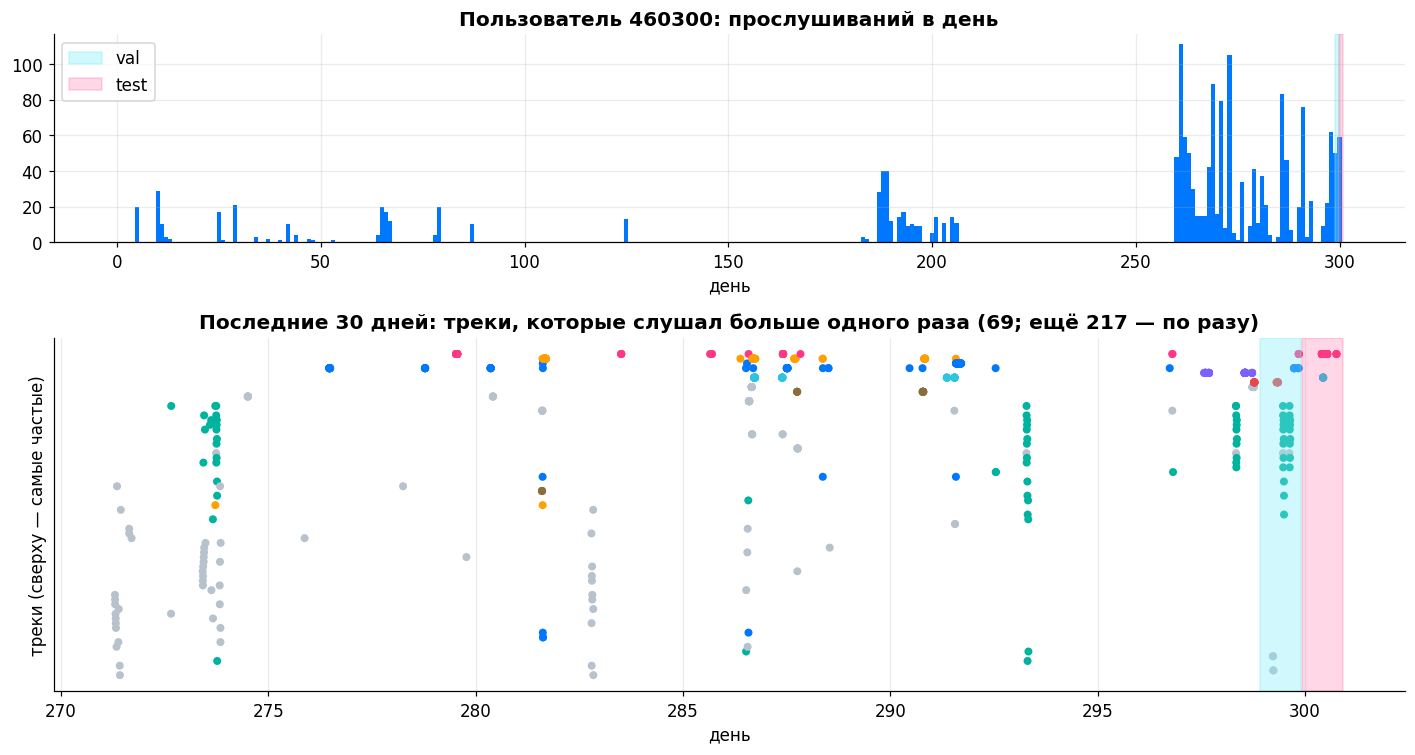

In [8]:
lens_all = pos.groupby('uid').size()
first_day = pos.groupby('uid').timestamp.min() // DAY
recent = pos[pos.timestamp >= LAST_TS - 30 * DAY]
active_days = (recent.timestamp // DAY).groupby(recent.uid).nunique()
cand = [u for u in test.uid.unique()
        if 800 <= lens_all[u] <= 6000 and first_day[u] < 20 and active_days.get(u, 0) >= 15] or list(test.uid.unique())
demo_uid = int(np.random.default_rng(1).choice(cand))
u = pos[pos.uid == demo_uid]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), gridspec_kw={'height_ratios': [1, 1.7]})
per_day = np.bincount((u.timestamp // DAY).to_numpy(), minlength=LAST_TS // DAY + 1)
ax1.bar(np.arange(len(per_day)), per_day, width=1.0, color=BLUE)
ax1.set(title=f'Пользователь {demo_uid}: прослушиваний в день', xlabel='день')

z = u[u.timestamp >= LAST_TS - 30 * DAY]
plays = z.item_id.value_counts()
n_once = (plays == 1).sum()
z = z[z.item_id.map(plays) > 1]
row = {it: k for k, it in enumerate(plays[plays > 1].index[::-1])}   # самые частые треки сверху
art = z.item_id.map(artist_of)
top_art = list(art.value_counts().index[:len(PALETTE)])
colors = [PALETTE[top_art.index(a)] if a in top_art else GRAY for a in art]
ax2.scatter(z.timestamp / DAY, z.item_id.map(row), c=colors, s=18)
ax2.set(title=f'Последние 30 дней: треки, которые слушал больше одного раза ({len(row)}; ещё {n_once} — по разу)',
        xlabel='день', ylabel='треки (сверху — самые частые)', yticks=[])
for ax in (ax1, ax2):
    ax.axvspan(VAL_START / DAY, VAL_END / DAY, color=CYAN, alpha=0.35, label='val')
    ax.axvspan(TEST_START / DAY, LAST_TS / DAY, color=PINK, alpha=0.2, label='test')
ax1.legend(loc='upper left')
plt.tight_layout(); plt.show()

В тесте считаем долю повторных прослушиваний.

In [9]:
test_org = test[test.is_organic == 1]
seen_pairs = pd.MultiIndex.from_frame(history_for_test[['uid', 'item_id']].drop_duplicates())
repeat_share = pd.MultiIndex.from_frame(test_org[['uid', 'item_id']]).isin(seen_pairs).mean()
print(f'повторы среди органических прослушиваний теста: {repeat_share:.0%}')

повторы среди органических прослушиваний теста: 83%


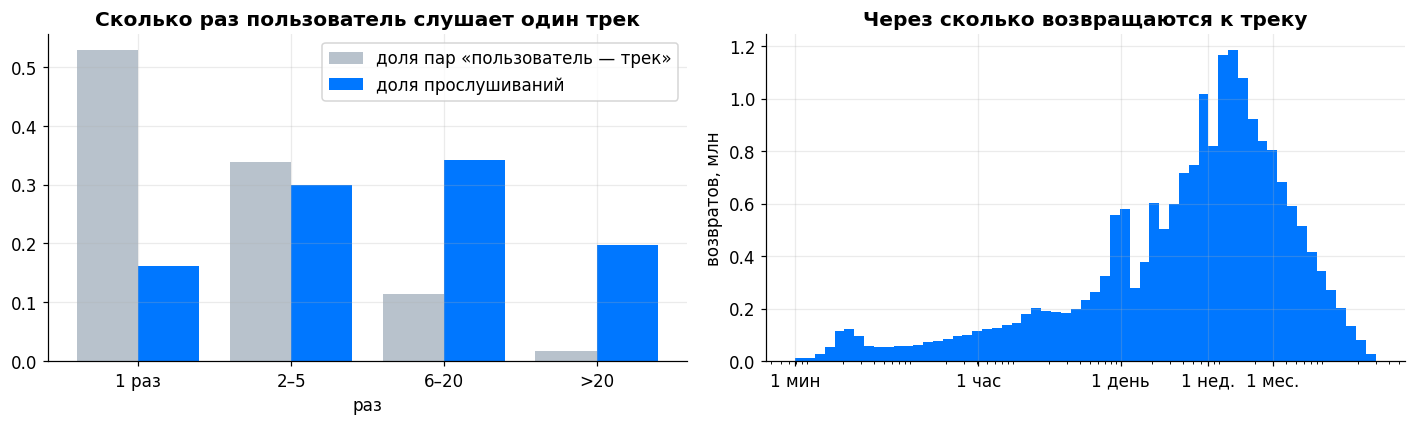

треки, которые слушали больше 5 раз, дают 54% всех прослушиваний train


In [10]:
pair = train.groupby(['uid', 'item_id']).size()
labels = ['1 раз', '2–5', '6–20', '>20']
bucket = pd.cut(pair, [0, 1, 5, 20, np.inf], labels=labels)
pairs_share = bucket.value_counts(normalize=True).reindex(labels)
listens_share = pair.groupby(bucket, observed=False).sum().reindex(labels) / pair.sum()
gaps_days = train.groupby(['uid', 'item_id']).timestamp.diff().dropna() / DAY
gaps_days = gaps_days[gaps_days >= 1 / 1440]           # дубли с одинаковым временем не считаем

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(labels))
axes[0].bar(x - 0.2, pairs_share, 0.4, color=GRAY, label='доля пар «пользователь — трек»')
axes[0].bar(x + 0.2, listens_share, 0.4, color=BLUE, label='доля прослушиваний')
axes[0].set(xticks=x, xticklabels=labels, title='Сколько раз пользователь слушает один трек', xlabel='раз')
axes[0].legend()
axes[1].hist(gaps_days, bins=np.logspace(np.log10(1 / 1440), np.log10(300), 60), color=BLUE)
ticks = {'1 мин': 1 / 1440, '1 час': 1 / 24, '1 день': 1, '1 нед.': 7, '1 мес.': 30}
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v / 1e6:.1f}'))
axes[1].set(xscale='log', xticks=list(ticks.values()), xticklabels=list(ticks.keys()),
            title='Через сколько возвращаются к треку', ylabel='возвратов, млн')
axes[1].grid(axis='x', alpha=0.25)
plt.tight_layout(); plt.show()
print(f'треки, которые слушали больше 5 раз, дают {listens_share.iloc[2:].sum():.0%} всех прослушиваний train')

**Каталог:** top-`catalog_size` треков train. `0` — PAD. Треки вне каталога исключаем из входа, но учитываем в тесте.

In [ ]:
item_counts = train.item_id.value_counts().sort_index().sort_values(ascending=False, kind='stable')
catalog = item_counts.index[:CFG['catalog_size']].to_numpy()
item2idx = pd.Series(np.arange(1, len(catalog) + 1), index=catalog)
N_ITEMS = len(catalog)

def encode(df):
    idx = df.item_id.map(item2idx)
    # вне каталога: уникальный отрицательный код, чтобы считать промахи по каждому треку отдельно
    return df.assign(idx=idx.fillna(-df.item_id.astype('int64')).astype('int64'))

train, val, test, history_for_test = map(encode, (train, val, test, history_for_test))
print(f'каталог: {N_ITEMS:,} треков, покрывает {(train.idx > 0).mean():.0%} событий train')

In [12]:
def build_seqs(df):
    d = df[df.idx > 0]
    return {u: g.to_numpy() for u, g in d.groupby('uid', sort=False).idx}

train_seqs = build_seqs(train)          # для обучения и как вход при валидации
test_input_seqs = build_seqs(history_for_test)   # вход при тесте

def build_targets(df, input_seqs, hist):
    d = df[(df.is_organic == 1) & df.uid.isin(input_seqs.keys())]
    nxt = d.groupby('uid').idx.first()
    all_ = d.groupby('uid').idx.agg(lambda s: list(dict.fromkeys(s)))
    targets = pd.DataFrame({'next': nxt.map(lambda x: [x]), 'all': all_})
    # для режима с фильтром: только треки, которых не было в истории, включая треки вне каталога
    seen = hist[hist.uid.isin(targets.index)].groupby('uid').idx.agg(set)
    for col in ('next', 'all'):
        targets[col + '_new'] = [[t for t in tgt if t not in seen[u]] for u, tgt in targets[col].items()]
    return targets

val_targets = build_targets(val, train_seqs, train)
test_targets = build_targets(test, test_input_seqs, history_for_test)
print(f'пользователей в val: {len(val_targets):,}, в test: {len(test_targets):,}')

# потолок: треки вне каталога не порекомендует ни одна модель
reach = lambda col: np.mean([t > 0 for tgt in test_targets[col] for t in tgt])
print(f"в каталоге: {reach('all'):.0%} таргетов all, {reach('next'):.0%} таргетов next, {reach('all_new'):.0%} новых треков")

пользователей в val: 3,234, в test: 3,237
в каталоге: 76% таргетов all, 76% таргетов next, 60% новых треков


## 3. Обучающие примеры
Окно `max_len + 1`, таргет сдвинут на один трек. PAD добавляем слева. За эпоху используем случайные окна.

In [13]:
def make_example(chunk, max_len):
    inp = chunk[:-1][-max_len:]
    tgt = chunk[1:][-max_len:]
    pad = max_len - len(inp)
    inp = np.pad(inp, (pad, 0))
    tgt = np.pad(tgt, (pad, 0))
    return torch.as_tensor(inp, dtype=torch.long), torch.as_tensor(tgt, dtype=torch.long)

In [14]:
inp, tgt = make_example(np.array([11, 12, 13, 14, 15]), max_len=6)
print('вход  ', inp.tolist())
print('таргет', tgt.tolist())
assert inp.tolist() == [0, 0, 11, 12, 13, 14] and tgt.tolist() == [0, 0, 12, 13, 14, 15]

вход   [0, 0, 11, 12, 13, 14]
таргет [0, 0, 12, 13, 14, 15]


In [15]:
class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, seqs, max_len, windows_per_user):
        self.max_len = max_len
        self.seqs, self.index = [], []
        for s in seqs.values():
            if len(s) < 2:
                continue
            n_windows = min(windows_per_user, math.ceil(len(s) / max_len))
            self.index += [len(self.seqs)] * n_windows
            self.seqs.append(s)

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        s = self.seqs[self.index[i]]
        L = self.max_len + 1
        start = np.random.randint(0, len(s) - L + 1) if len(s) > L else 0
        return make_example(s[start:start + L], self.max_len)

train_ds = WindowDataset(train_seqs, CFG['max_len'], CFG['windows_per_user'])
train_dl = torch.utils.data.DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True, drop_last=True)
print(f'{len(train_ds):,} окон за эпоху, {len(train_dl):,} батчей')

63,571 окон за эпоху, 993 батчей


## 4. Метрики и бейзлайны
Precision@K, Recall@K, NDCG@K. Таргеты: `next` и `all`; режимы: с фильтром повторов и без. В режиме с фильтром исключаем повторы и из выдачи, и из таргета.

In [16]:
def history_matrix(seqs, users):
    rows, cols = [], []
    for r, u in enumerate(users):
        s = seqs.get(u, np.zeros(0, dtype=np.int64))
        rows.append(np.full(len(s), r)); cols.append(s)
    data = np.ones(sum(len(c) for c in cols), dtype=np.float32)
    return sp.csr_matrix((data, (np.concatenate(rows), np.concatenate(cols))), shape=(len(users), N_ITEMS + 1))


def ndcg(hits, n_rel, k):
    disc = 1 / np.log2(np.arange(2, k + 2))
    return (hits * disc).sum() / disc[:min(n_rel, k)].sum()


def evaluate(score_fn, targets, input_seqs, ks=(10, 100), batch=512, per_user=False, filters=(False, True)):
    users = targets.index.to_numpy()
    H = history_matrix(input_seqs, users)
    rows, per_user_rows = [], []
    for filt in filters:
        recs = []
        for b in range(0, len(users), batch):
            scores = np.asarray(score_fn(users[b:b + batch]), dtype=np.float32).copy()
            scores[:, 0] = -np.inf
            if filt:
                h = H[b:b + batch].tocoo()
                scores[h.row, h.col] = -np.inf
            top = np.argpartition(-scores, max(ks), axis=1)[:, :max(ks)]
            order = np.take_along_axis(scores, top, 1).argsort(axis=1)[:, ::-1]
            recs.append(np.take_along_axis(top, order, 1))
        recs = np.vstack(recs)
        for target in ('next', 'all'):
            m = {f'{n}@{k}': [] for k in ks for n in ('Precision', 'Recall', 'NDCG')}
            kept = []
            for r, (u, tgt) in enumerate(zip(users, targets[target + '_new' if filt else target])):
                if not tgt:
                    continue
                kept.append(u)
                for k in ks:
                    hits = np.isin(recs[r, :k], tgt).astype(float)
                    m[f'Precision@{k}'].append(hits.sum() / k)
                    m[f'Recall@{k}'].append(hits.sum() / len(tgt))
                    m[f'NDCG@{k}'].append(ndcg(hits, len(tgt), k))
            rows.append({'filtered': filt, 'target': target, 'users': len(kept),
                         **{k_: np.mean(v) for k_, v in m.items()}})
            if per_user:
                per_user_rows.append(pd.DataFrame({'uid': kept, 'filtered': filt, 'target': target,
                                                   'NDCG@10': m['NDCG@10']}))
    res = pd.DataFrame(rows)
    return (res, pd.concat(per_user_rows)) if per_user else res


RESULTS = {}
def report(name, res):
    RESULTS[name] = res
    show = res.set_index(['filtered', 'target'])[['NDCG@10', 'Recall@10', 'Recall@100', 'Precision@10']]
    print(name); display(show.round(4))

**Popular:** топ популярных треков.

In [17]:
pop_scores = np.zeros(N_ITEMS + 1, dtype=np.float32)
pop_counts = train[train.idx > 0].idx.value_counts()
pop_scores[pop_counts.index] = pop_counts.values
pop_scores /= pop_scores.max()

score_popular = lambda users: np.tile(pop_scores, (len(users), 1))
report('Popular', evaluate(score_popular, test_targets, test_input_seqs))

Popular


NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.0045     0.0096      0.0395        0.0010
         all      0.0172     0.0104      0.0426        0.0131
True     next     0.0011     0.0024      0.0228        0.0002
         all      0.0051     0.0055      0.0224        0.0028

**Повтор истории:** самые частые треки пользователя.

In [18]:
def make_repeat(seqs):
    def score(users):
        H = history_matrix(seqs, users)                  # счётчики прослушиваний
        return H.toarray() + 1e-3 * pop_scores           # ничьи разрешаем популярностью
    return score

score_repeat = make_repeat(test_input_seqs)
report('Повтор истории', evaluate(score_repeat, test_targets, test_input_seqs))

Повтор истории


NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.0599     0.1035      0.3244        0.0103
         all      0.1395     0.0961      0.3372        0.1114
True     next     0.0011     0.0024      0.0228        0.0002
         all      0.0051     0.0055      0.0224        0.0028

**ItemKNN, iALS:** обучаем по матрице user–item.

In [19]:
from implicit.nearest_neighbours import CosineRecommender
from implicit.als import AlternatingLeastSquares

train_users = np.array(list(train_seqs.keys()))
uid2row = {u: r for r, u in enumerate(train_users)}
X_train = history_matrix(train_seqs, train_users)
X_train.data[:] = 1.0                                     # бинарная матрица
X_train = X_train.tocsr()

knn = CosineRecommender(K=100)
knn.fit(X_train, show_progress=False)
S = knn.similarity.tocsr()                                # трек × трек, top-100 соседей

def score_itemknn(users):
    H = history_matrix(test_input_seqs, users); H.data[:] = 1.0
    return (H @ S).toarray() + 1e-3 * pop_scores

report('ItemKNN', evaluate(score_itemknn, test_targets, test_input_seqs))

ItemKNN


NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.0052     0.0117      0.0797        0.0012
         all      0.0285     0.0158      0.0908        0.0242
True     next     0.0011     0.0036      0.0432        0.0004
         all      0.0063     0.0067      0.0455        0.0035

In [20]:
als = AlternatingLeastSquares(factors=64, regularization=0.05, iterations=15, random_state=SEED, use_gpu=False)
als.fit(X_train, show_progress=False)
U, V = np.asarray(als.user_factors), np.asarray(als.item_factors)

U0 = np.vstack([U, np.zeros((1, U.shape[1]), dtype=U.dtype)])   # последняя строка — для пользователей без train

def score_ials(users):
    rows = np.array([uid2row.get(u, len(U)) for u in users])
    return U0[rows] @ V.T + 1e-3 * pop_scores

report('iALS', evaluate(score_ials, test_targets, test_input_seqs))

iALS


NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.0069     0.0130      0.0853        0.0013
         all      0.0297     0.0167      0.0907        0.0250
True     next     0.0039     0.0060      0.0432        0.0006
         all      0.0078     0.0089      0.0499        0.0046

**Последний айтем:** соседи последнего трека по ItemKNN.

In [21]:
def make_last_item(seqs):
    def score(users):
        last = np.array([seqs[u][-1] for u in users])
        return S[last].toarray() + 1e-3 * pop_scores
    return score

score_last_item = make_last_item(test_input_seqs)

report('Соседи последнего айтема', evaluate(score_last_item, test_targets, test_input_seqs))

Соседи последнего айтема


NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.0689     0.0856      0.1415        0.0086
         all      0.0919     0.0571      0.1086        0.0493
True     next     0.0172     0.0300      0.0624        0.0030
         all      0.0169     0.0192      0.0498        0.0075

**Потолок каталога:** идеальное ранжирование доступных таргетов (оракул).

In [22]:
def make_oracle(targets):
    def score(users):
        s = np.zeros((len(users), N_ITEMS + 1), dtype=np.float32)
        for r, u in enumerate(users):
            for col, w in (('all', 1), ('next', 2)):
                s[r, [t for t in targets.at[u, col] if t > 0]] = w     # вне каталога порекомендовать нельзя
        return s
    return score

report('Потолок каталога', evaluate(make_oracle(test_targets), test_targets, test_input_seqs))

Потолок каталога


NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.7550     0.7550      0.7550        0.0755
         all      0.8526     0.6019      0.7516        0.6083
True     next     0.6055     0.6055      0.6055        0.0606
         all      0.6848     0.5993      0.6250        0.2780

## 5. SASRec
Эмбеддинги треков и позиций → self-attention → скор по скалярному произведению. Causal mask скрывает будущее, padding mask — PAD. Диагональ разрешена, чтобы избежать NaN на PAD-позициях.

In [23]:
class SASRec(nn.Module):
    def __init__(self, n_items, max_len, d_model, n_heads, n_layers, dropout, causal=True):
        super().__init__()
        self.item_emb = nn.Embedding(n_items + 1, d_model, padding_idx=0)
        self.pos_emb = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.n_heads, self.causal = n_heads, causal
        nn.init.normal_(self.item_emb.weight, std=0.02)
        nn.init.normal_(self.pos_emb.weight, std=0.02)
        with torch.no_grad():
            self.item_emb.weight[0].zero_()

    def attention_mask(self, seq):
        B, L = seq.shape
        eye = torch.eye(L, dtype=torch.bool, device=seq.device)
        future = torch.triu(torch.ones(L, L, dtype=torch.bool, device=seq.device), diagonal=1)
        pad = (seq == 0)[:, None, :].expand(B, L, L)
        mask = (pad | future) if self.causal else pad
        mask = mask & ~eye
        return mask.repeat_interleave(self.n_heads, dim=0)

    def forward(self, seq):
        pos = torch.arange(seq.shape[1], device=seq.device)
        x = self.drop(self.item_emb(seq) + self.pos_emb(pos))
        x = self.encoder(x, mask=self.attention_mask(seq))
        return self.norm(x)

    def scores(self, h):
        return h @ self.item_emb.weight.T

In [24]:
m = SASRec(10, 4, 8, 2, 1, 0.0)
mask = m.attention_mask(torch.tensor([[0, 0, 3, 4]]))[0]
print((~mask).int())        # 1 = смотреть можно
assert (~mask).int().tolist() == [[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 1, 1]]

tensor([[1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0],
        [0, 0, 1, 1]], dtype=torch.int32)


**Лоссы:** CE — softmax по каталогу; BCE — позитив и случайные негативы. PAD и треки текущего окна не сэмплируем как негативы.

In [25]:
def ce_loss(model, inp, tgt):
    valid = tgt > 0
    h = model(inp)[valid]
    logits = model.scores(h)
    logits[:, 0] = -torch.inf
    return F.cross_entropy(logits, tgt[valid])


def sample_negatives(inp, tgt, n_neg):
    """[B, L, n_neg] случайных треков из 1..N_ITEMS (без PAD), кроме треков текущего окна."""
    window = torch.cat([inp, tgt], 1)                               # [B, 2L]: все треки окна
    neg = torch.randint(1, N_ITEMS + 1, (*tgt.shape, n_neg), device=tgt.device)
    while True:
        bad = (neg[..., None] == window[:, None, None, :]).any(-1)  # негатив совпал с треком окна
        if not bad.any():
            return neg
        neg[bad] = torch.randint(1, N_ITEMS + 1, (int(bad.sum()),), device=tgt.device)


def bce_loss(model, inp, tgt, n_neg=CFG['n_neg']):
    valid = tgt > 0
    h = model(inp)[valid]                                       # [N, d]
    pos_items = tgt[valid]                                      # [N]
    neg_items = sample_negatives(inp, tgt, n_neg)[valid]        # [N, n_neg]
    s_pos = (h * model.item_emb(pos_items)).sum(-1)             # [N]
    s_neg = (h[:, None, :] * model.item_emb(neg_items)).sum(-1) # [N, n_neg]
    return (-F.logsigmoid(s_pos) - F.logsigmoid(-s_neg).sum(-1)).mean()


_w = torch.randint(1, N_ITEMS + 1, (8, CFG['max_len']))
assert not (sample_negatives(_w, _w, 3)[..., None] == _w[:, None, None, :]).any()     # в негативах нет треков окна


**Обучение:** выбираем лучшую эпоху по NDCG@10 на val. `PRETRAINED=True` загружает сохранённые веса.

In [26]:
def make_score_fn(model, input_seqs, max_len):
    @torch.no_grad()
    def score(users):
        model.eval()
        seqs = [input_seqs[u][-max_len:] for u in users]
        batch = torch.tensor(np.stack([np.pad(s, (max_len - len(s), 0)) for s in seqs]), device=DEVICE)
        h = model(batch)[:, -1]
        return model.scores(h).float().cpu().numpy()
    return score


def val_score(score_fn):
    n = CFG['eval_users_val']
    tg = val_targets if n is None else val_targets.sample(n, random_state=SEED)
    res = evaluate(score_fn, tg, train_seqs, ks=(10,), filters=(False,))   # для выбора эпохи нужен только all без фильтра
    return res.query('filtered == False and target == "all"')['NDCG@10'].item()


def val_ndcg(model):
    return val_score(make_score_fn(model, train_seqs, CFG['max_len']))


def new_model(causal=True):
    return SASRec(N_ITEMS, CFG['max_len'], CFG['d_model'], CFG['n_heads'], CFG['n_layers'],
                  CFG['dropout'], causal=causal).to(DEVICE)


def train_model(loss_fn, causal=True, epochs=CFG['epochs'], max_steps=None, log_every=200):
    model = new_model(causal)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=0.01)
    best, best_state, losses, val_hist, step = -1, None, [], [], 0
    for epoch in range(epochs):
        model.train(); t0 = time.time()
        for inp, tgt in train_dl:
            loss = loss_fn(model, inp.to(DEVICE), tgt.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item()); step += 1
            if step % log_every == 0:
                print(f'  шаг {step}: loss {np.mean(losses[-log_every:]):.3f}')
            if max_steps and step >= max_steps:
                break
        score = val_ndcg(model); val_hist.append(score)
        print(f'эпоха {epoch + 1}: loss {np.mean(losses[-len(train_dl):]):.3f}, val NDCG@10 {score:.4f}, {time.time() - t0:.0f} с')
        if score > best:
            best, best_state = score, {k: v.detach().clone() for k, v in model.state_dict().items()}
        if max_steps and step >= max_steps:
            break
    model.load_state_dict(best_state)
    return model, losses, val_hist


CKPT = {'ce': f'{ART_DIR}/sasrec_ce.pt', 'bce': f'{ART_DIR}/sasrec_bce.pt'}
HIST_PATH, CATALOG_PATH = f'{ART_DIR}/history.json', f'{ART_DIR}/catalog_item_ids.npy'
LOAD = PRETRAINED and all(os.path.exists(p) for p in [*CKPT.values(), HIST_PATH, CATALOG_PATH])
HIST = json.load(open(HIST_PATH)) if LOAD else {}   # кривые обучения: val NDCG по эпохам и train loss
print('модели загружаем из artifacts/' if LOAD else
      'обучаем модели' + (' (в artifacts/ нет сохранённых)' if PRETRAINED else ''))


def load_model(name):
    if not np.array_equal(np.load(CATALOG_PATH), catalog):
        raise ValueError(f'{ART_DIR}/ сохранён для другого каталога (QUICK или другие данные). '
                         'Поставьте PRETRAINED = False или положите подходящие артефакты.')
    ckpt = torch.load(CKPT[name], map_location=DEVICE, weights_only=True)
    model = new_model()
    model.load_state_dict(ckpt['state_dict'])
    return model.eval()


обучаем модели (в artifacts/ нет сохранённых)


In [27]:
if LOAD:
    sasrec_ce, losses_ce, val_ce = load_model('ce'), HIST['losses_ce'], HIST['val_ce']
else:
    sasrec_ce, losses_ce, val_ce = train_model(ce_loss)
report('SASRec · CE', evaluate(make_score_fn(sasrec_ce, test_input_seqs, CFG['max_len']), test_targets, test_input_seqs))

  шаг 200: loss 10.038
  шаг 400: loss 9.596
  шаг 600: loss 9.302
  шаг 800: loss 8.997
эпоха 1: loss 9.328, val NDCG@10 0.0401, 63 с
  шаг 1000: loss 8.682
  шаг 1200: loss 8.470
  шаг 1400: loss 8.328
  шаг 1600: loss 8.215
  шаг 1800: loss 8.120
эпоха 2: loss 8.239, val NDCG@10 0.0657, 64 с
  шаг 2000: loss 8.026
  шаг 2200: loss 7.963
  шаг 2400: loss 7.918
  шаг 2600: loss 7.897
  шаг 2800: loss 7.853
эпоха 3: loss 7.892, val NDCG@10 0.0839, 64 с
  шаг 3000: loss 7.819
  шаг 3200: loss 7.762
  шаг 3400: loss 7.754
  шаг 3600: loss 7.709
  шаг 3800: loss 7.692
эпоха 4: loss 7.722, val NDCG@10 0.0940, 64 с
  шаг 4000: loss 7.674
  шаг 4200: loss 7.634
  шаг 4400: loss 7.635
  шаг 4600: loss 7.607
  шаг 4800: loss 7.589
эпоха 5: loss 7.614, val NDCG@10 0.1041, 64 с
  шаг 5000: loss 7.591
  шаг 5200: loss 7.553
  шаг 5400: loss 7.554
  шаг 5600: loss 7.527
  шаг 5800: loss 7.516
эпоха 6: loss 7.536, val NDCG@10 0.1112, 64 с
  шаг 6000: loss 7.514
  шаг 6200: loss 7.482
  шаг 6400: lo

NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.0827     0.1254      0.2681        0.0125
         all      0.1311     0.0901      0.2238        0.0888
True     next     0.0184     0.0348      0.0959        0.0035
         all      0.0236     0.0278      0.0936        0.0123

In [28]:
if LOAD:
    sasrec_bce, losses_bce, val_bce = load_model('bce'), HIST['losses_bce'], HIST['val_bce']
else:
    sasrec_bce, losses_bce, val_bce = train_model(bce_loss)
report('SASRec · BCE', evaluate(make_score_fn(sasrec_bce, test_input_seqs, CFG['max_len']), test_targets, test_input_seqs))

  шаг 200: loss 1.162
  шаг 400: loss 1.009
  шаг 600: loss 0.930
  шаг 800: loss 0.861
эпоха 1: loss 0.951, val NDCG@10 0.0191, 16 с
  шаг 1000: loss 0.787
  шаг 1200: loss 0.729
  шаг 1400: loss 0.694
  шаг 1600: loss 0.662
  шаг 1800: loss 0.637
эпоха 2: loss 0.668, val NDCG@10 0.0248, 15 с
  шаг 2000: loss 0.610
  шаг 2200: loss 0.593
  шаг 2400: loss 0.579
  шаг 2600: loss 0.567
  шаг 2800: loss 0.555
эпоха 3: loss 0.569, val NDCG@10 0.0333, 15 с
  шаг 3000: loss 0.547
  шаг 3200: loss 0.537
  шаг 3400: loss 0.533
  шаг 3600: loss 0.523
  шаг 3800: loss 0.519
эпоха 4: loss 0.526, val NDCG@10 0.0348, 15 с
  шаг 4000: loss 0.511
  шаг 4200: loss 0.505
  шаг 4400: loss 0.505
  шаг 4600: loss 0.499
  шаг 4800: loss 0.497
эпоха 5: loss 0.501, val NDCG@10 0.0353, 15 с
  шаг 5000: loss 0.494
  шаг 5200: loss 0.488
  шаг 5400: loss 0.484
  шаг 5600: loss 0.482
  шаг 5800: loss 0.481
эпоха 6: loss 0.482, val NDCG@10 0.0412, 15 с
  шаг 6000: loss 0.475
  шаг 6200: loss 0.472
  шаг 6400: los

NDCG@10  Recall@10  Recall@100  Precision@10
filtered target                                              
False    next     0.0289     0.0516      0.1786        0.0052
         all      0.0562     0.0395      0.1489        0.0427
True     next     0.0080     0.0180      0.0707        0.0018
         all      0.0110     0.0127      0.0671        0.0063

NDCG@10 по эпохам, рядом — бейзлайны.

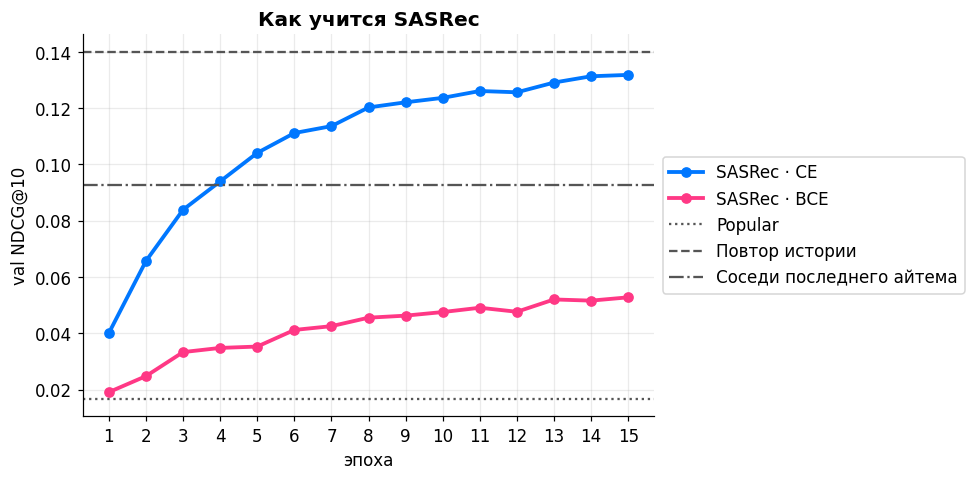

In [29]:
base_val = {'Popular': val_score(score_popular),
            'Повтор истории': val_score(make_repeat(train_seqs)),
            'Соседи последнего айтема': val_score(make_last_item(train_seqs))}
plt.figure(figsize=(9, 4.5))
plt.plot(np.arange(1, len(val_ce) + 1), val_ce, 'o-', color=BLUE, lw=2.5, label='SASRec · CE')
plt.plot(np.arange(1, len(val_bce) + 1), val_bce, 'o-', color=PINK, lw=2.5, label='SASRec · BCE')
for (name, v), ls in zip(base_val.items(), [':', '--', '-.']):
    plt.axhline(v, color='#555555', ls=ls, lw=1.5, label=name)
plt.xticks(np.arange(1, len(val_ce) + 1))
plt.xlabel('эпоха'); plt.ylabel('val NDCG@10'); plt.title('Как учится SASRec')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.tight_layout(); plt.show()

## 6. Оценка
### Итоговая таблица

In [30]:
def results_table(filter_, target):
    rows = {name: r.query('filtered == @filter_ and target == @target').iloc[0] for name, r in RESULTS.items()}
    return pd.DataFrame(rows).T[['NDCG@10', 'Recall@10', 'Recall@100', 'Precision@10']].astype(float).round(4)

for filter_ in (False, True):
    for target in ('all', 'next'):
        print(f'фильтр повторов: {filter_}, таргет: {target}')
        display(results_table(filter_, target))

фильтр повторов: False, таргет: all


,NDCG@10,Recall@10,Recall@100,Precision@10
Popular,0.0172,0.0104,0.0426,0.0131
Повтор истории,0.1395,0.0961,0.3372,0.1114
ItemKNN,0.0285,0.0158,0.0908,0.0242
iALS,0.0297,0.0167,0.0907,0.0250
Соседи последнего айтема,0.0919,0.0571,0.1086,0.0493
Потолок каталога,0.8526,0.6019,0.7516,0.6083
SASRec · CE,0.1311,0.0901,0.2238,0.0888
SASRec · BCE,0.0562,0.0395,0.1489,0.0427


фильтр повторов: False, таргет: next


,NDCG@10,Recall@10,Recall@100,Precision@10
Popular,0.0045,0.0096,0.0395,0.0010
Повтор истории,0.0599,0.1035,0.3244,0.0103
ItemKNN,0.0052,0.0117,0.0797,0.0012
iALS,0.0069,0.0130,0.0853,0.0013
Соседи последнего айтема,0.0689,0.0856,0.1415,0.0086
Потолок каталога,0.7550,0.7550,0.7550,0.0755
SASRec · CE,0.0827,0.1254,0.2681,0.0125
SASRec · BCE,0.0289,0.0516,0.1786,0.0052


фильтр повторов: True, таргет: all


,NDCG@10,Recall@10,Recall@100,Precision@10
Popular,0.0051,0.0055,0.0224,0.0028
Повтор истории,0.0051,0.0055,0.0224,0.0028
ItemKNN,0.0063,0.0067,0.0455,0.0035
iALS,0.0078,0.0089,0.0499,0.0046
Соседи последнего айтема,0.0169,0.0192,0.0498,0.0075
Потолок каталога,0.6848,0.5993,0.6250,0.2780
SASRec · CE,0.0236,0.0278,0.0936,0.0123
SASRec · BCE,0.0110,0.0127,0.0671,0.0063


фильтр повторов: True, таргет: next


,NDCG@10,Recall@10,Recall@100,Precision@10
Popular,0.0011,0.0024,0.0228,0.0002
Повтор истории,0.0011,0.0024,0.0228,0.0002
ItemKNN,0.0011,0.0036,0.0432,0.0004
iALS,0.0039,0.0060,0.0432,0.0006
Соседи последнего айтема,0.0172,0.0300,0.0624,0.0030
Потолок каталога,0.6055,0.6055,0.6055,0.0606
SASRec · CE,0.0184,0.0348,0.0959,0.0035
SASRec · BCE,0.0080,0.0180,0.0707,0.0018


### Результаты
- `all`, без фильтра: повтор истории — **0.1395**, SASRec CE — **0.1311** по NDCG@10.
- `next`, без фильтра: SASRec CE — **0.0827**, соседи последнего айтема — **0.0689**.
- `all`, с фильтром: SASRec CE — **0.0236**, соседи — **0.0169**.
- CE лучше BCE: **0.1311** против **0.0562** (`all`, без фильтра).

### Повторы
83% органических прослушиваний теста — уже знакомые треки. Сравниваем качество на повторах и новых треках отдельно.

таргетов-повторов: 40,126, новых: 10,971 (79% повторов)


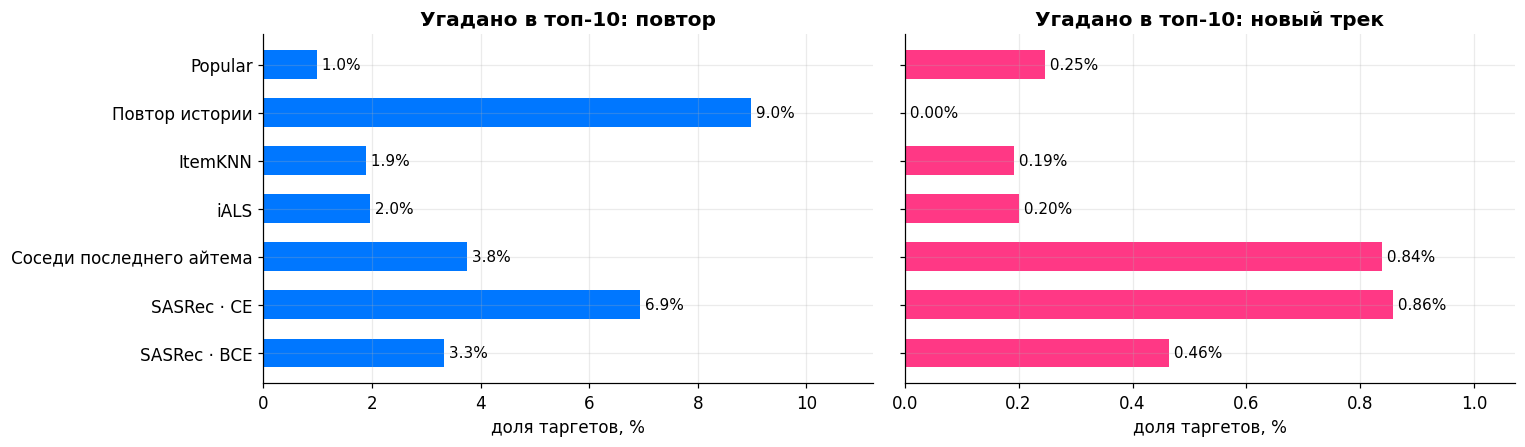

,повтор,новый трек
модель,,
Popular,0.0099,0.0025
Повтор истории,0.0898,0.0000
ItemKNN,0.0190,0.0019
iALS,0.0196,0.0020
Соседи последнего айтема,0.0375,0.0084
SASRec · CE,0.0693,0.0086
SASRec · BCE,0.0332,0.0046


In [31]:
def top_k(score_fn, users, k, batch=512):
    """Топ-k индексов треков без фильтра повторов (PAD исключён)."""
    out = []
    for b in range(0, len(users), batch):
        s = np.asarray(score_fn(users[b:b + batch]), dtype=np.float32).copy()
        s[:, 0] = -np.inf
        top = np.argpartition(-s, k, axis=1)[:, :k]
        order = np.take_along_axis(s, top, 1).argsort(axis=1)[:, ::-1]
        out.append(np.take_along_axis(top, order, 1))
    return np.vstack(out)


MODELS = {'Popular': score_popular, 'Повтор истории': score_repeat, 'ItemKNN': score_itemknn, 'iALS': score_ials,
          'Соседи последнего айтема': score_last_item,
          'SASRec · CE': make_score_fn(sasrec_ce, test_input_seqs, CFG['max_len']),
          'SASRec · BCE': make_score_fn(sasrec_bce, test_input_seqs, CFG['max_len'])}
test_users = test_targets.index.to_numpy()
TOP100 = {name: top_k(fn, test_users, 100) for name, fn in MODELS.items()}   # пригодится и ниже

seen_all = history_for_test.groupby('uid').idx.agg(set)   # вся история, включая треки вне каталога (отрицательные коды)
seen = [seen_all[u] for u in test_users]
groups = ['повтор', 'новый трек']
rows = []
for name, recs in TOP100.items():
    hit, total = dict.fromkeys(groups, 0), dict.fromkeys(groups, 0)
    for r, (tgt, s) in enumerate(zip(test_targets['all'], seen)):
        top10 = set(recs[r, :10])
        for t in tgt:
            g = 'повтор' if t in s else 'новый трек'
            hit[g] += t in top10
            total[g] += 1
    rows.append({'модель': name, **{g: hit[g] / total[g] for g in groups}})
hits = pd.DataFrame(rows).set_index('модель')
print(f"таргетов-повторов: {total['повтор']:,}, новых: {total['новый трек']:,} "
      f"({total['повтор'] / (total['повтор'] + total['новый трек']):.0%} повторов)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
y = np.arange(len(hits))[::-1]
for ax, g, color in zip(axes, groups, [BLUE, PINK]):
    ax.barh(y, hits[g] * 100, color=color, height=0.6)
    for yi, v in zip(y, hits[g] * 100):
        ax.text(v, yi, f' {v:.1f}%' if g == 'повтор' else f' {v:.2f}%', va='center', fontsize=10)
    ax.set(title=f'Угадано в топ-10: {g}', xlabel='доля таргетов, %')
    ax.set_xlim(0, hits[g].max() * 100 * 1.25)
axes[0].set_yticks(y, hits.index)
plt.tight_layout(); plt.show()
hits.round(4)

### Популярность
Сравниваем популярность рекомендаций и Coverage@100.

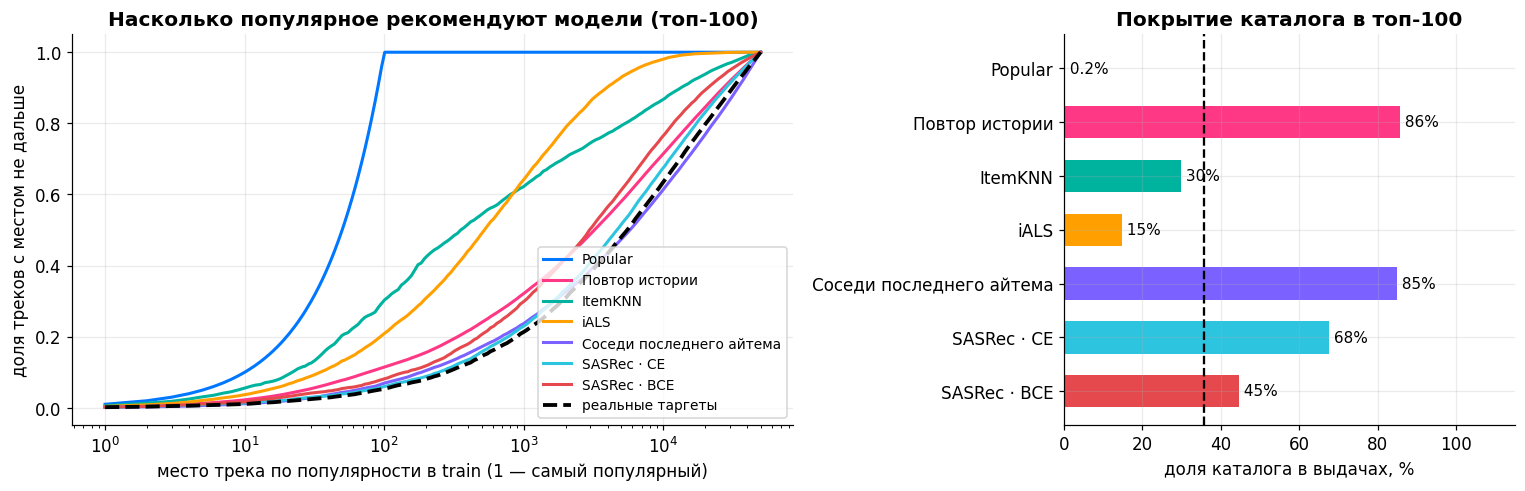

треков каталога среди реальных таргетов: 36% (пунктир справа)


In [32]:
tgt_idx = np.sort([t for tgt in test_targets['all'] for t in tgt if t > 0])   # таргеты из каталога
grid = np.unique(np.logspace(0, np.log10(N_ITEMS), 200).astype(int))
ecdf = lambda v: np.searchsorted(np.sort(v), grid, side='right') / len(v)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
for (name, recs), color in zip(TOP100.items(), PALETTE):
    ax.plot(grid, ecdf(recs.ravel()), color=color, lw=2, label=name)
ax.plot(grid, ecdf(tgt_idx), color='black', lw=2.5, ls='--', label='реальные таргеты')
ax.set(xscale='log', xlabel='место трека по популярности в train (1 — самый популярный)',
       ylabel='доля треков с местом не дальше', title='Насколько популярное рекомендуют модели (топ-100)')
ax.legend(fontsize=9, loc='lower right')

coverage = pd.Series({name: len(np.unique(recs)) / N_ITEMS for name, recs in TOP100.items()})
ax = axes[1]
y = np.arange(len(coverage))[::-1]
ax.barh(y, coverage * 100, color=PALETTE[:len(coverage)], height=0.6)
for yi, v in zip(y, coverage * 100):
    ax.text(v, yi, f' {v:.0f}%' if v >= 1 else f' {v:.1f}%', va='center', fontsize=10)
ax.axvline(len(np.unique(tgt_idx)) / N_ITEMS * 100, color='black', ls='--', lw=1.5)
ax.set_yticks(y, coverage.index)
ax.set(xlim=(0, 115), xlabel='доля каталога в выдачах, %', title='Покрытие каталога в топ-100')
plt.tight_layout(); plt.show()
print(f'треков каталога среди реальных таргетов: {len(np.unique(tgt_idx)) / N_ITEMS:.0%} (пунктир справа)')

### Без causal mask
При обучении возникает утечка будущего: train-loss падает. На инференсе последняя позиция будущего не видит.

эпоха 1: loss 9.619, val NDCG@10 0.0251, 40 с
эпоха 1: loss 7.440, val NDCG@10 0.0448, 40 с


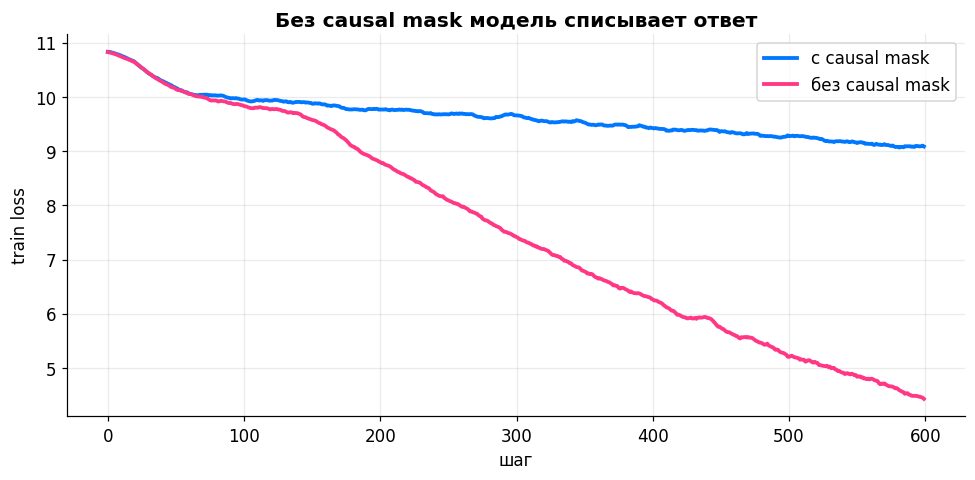

val NDCG@10: с causal mask 0.0251, без causal mask 0.0448


In [33]:
if LOAD:
    losses_causal, val_causal = HIST['losses_causal'], HIST['val_causal']
    losses_leak, val_leak = HIST['losses_leak'], HIST['val_leak']
else:
    steps = 100 if QUICK else 600
    _, losses_causal, val_causal = train_model(ce_loss, causal=True, epochs=1, max_steps=steps, log_every=10**9)
    _, losses_leak, val_leak = train_model(ce_loss, causal=False, epochs=1, max_steps=steps, log_every=10**9)
smooth = lambda x: pd.Series(x).rolling(20, min_periods=1).mean()
plt.figure(figsize=(9, 4.5))
plt.plot(smooth(losses_causal), color=BLUE, lw=2.5, label='с causal mask')
plt.plot(smooth(losses_leak), color=PINK, lw=2.5, label='без causal mask')
plt.xlabel('шаг'); plt.ylabel('train loss'); plt.title('Без causal mask модель списывает ответ'); plt.legend()
plt.tight_layout(); plt.show()
print(f'val NDCG@10: с causal mask {val_causal[-1]:.4f}, без causal mask {val_leak[-1]:.4f}')

### Внимание
Сравниваем веса внимания для треков одной сессии и более ранних событий. Внимание само по себе не равно важности.

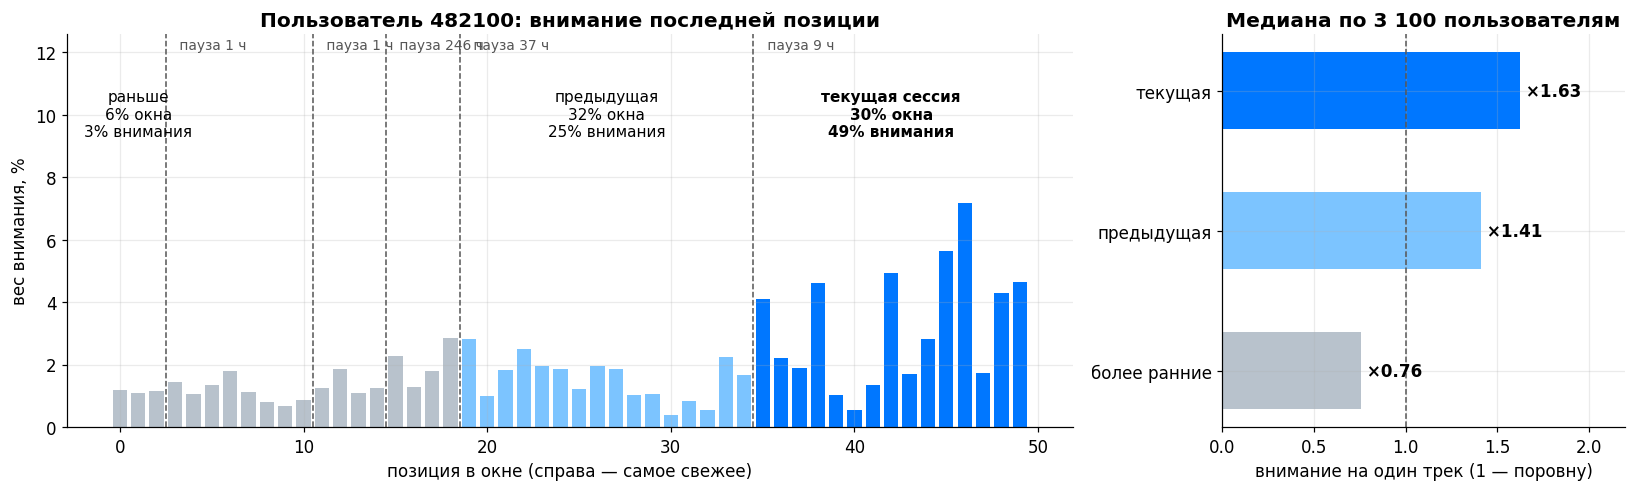

In [34]:
@torch.no_grad()
def attention_maps(model, seq):
    """Матрицы внимания всех слоёв (среднее по головам) для последних max_len событий."""
    model.eval()
    L = CFG['max_len']
    seq = seq[-L:]
    x = torch.tensor(np.pad(seq, (L - len(seq), 0)), device=DEVICE)[None]
    mask = model.attention_mask(x)
    h = model.item_emb(x) + model.pos_emb(torch.arange(L, device=DEVICE))
    maps = []
    for layer in model.encoder.layers:
        z = layer.norm1(h)
        _, w = layer.self_attn(z, z, z, attn_mask=mask, need_weights=True, average_attn_weights=True)
        maps.append(w[0].float().cpu().numpy())
        h = layer(h, src_mask=mask)
    return maps


L, GAP_S = CFG['max_len'], 30 * 60
hist_cat = history_for_test[history_for_test.idx > 0]
ts_cat = {u: g.to_numpy() for u, g in hist_cat.groupby('uid', sort=False).timestamp}       # выровнено с test_input_seqs
ts_all = {u: g.to_numpy() for u, g in pos[pos.timestamp < VAL_END].groupby('uid', sort=False).timestamp}


def window_sessions(u):
    """Сессия каждого из последних L событий: 0 — текущая, -1 — предыдущая и так далее."""
    a = ts_all[u]
    sess_all = np.concatenate([[0], np.cumsum(np.diff(a) > GAP_S)])
    ts = ts_cat[u][-L:]
    s = sess_all[np.searchsorted(a, ts, side='right') - 1]
    return s - s[-1], ts


rows = {}
for u in test_targets.index:
    if len(test_input_seqs[u]) < L:
        continue
    sess, ts = window_sessions(u)
    if sess.min() == 0:                       # в окне одна сессия — сравнивать не с чем
        continue
    att = attention_maps(sasrec_ce, test_input_seqs[u])[-1][-1]
    rel = lambda m: att[m].mean() * L if m.any() else np.nan
    rows[u] = {'текущая': rel(sess == 0), 'предыдущая': rel(sess == -1), 'более ранние': rel(sess <= -2),
               'n_sess': 1 - sess.min(), 'cur_len': (sess == 0).sum()}
att_df = pd.DataFrame.from_dict(rows, orient='index')
med = att_df[['текущая', 'предыдущая', 'более ранние']].median()

# пример: несколько сессий в окне, текущая не слишком короткая, отношение близко к медиане
cand = att_df[att_df.n_sess.between(3, 6) & att_df.cur_len.between(10, 22)]
ex_uid = (cand['текущая'] - med['текущая']).abs().idxmin()
sess, ts = window_sessions(ex_uid)
att = attention_maps(sasrec_ce, test_input_seqs[ex_uid])[-1][-1] * 100

LBLUE = '#7CC4FF'
fig, (ax, bx) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [2.5, 1]})
ax.bar(np.arange(L), att, width=0.78, color=np.where(sess == 0, BLUE, np.where(sess == -1, LBLUE, GRAY)))
ymax = att.max() * 1.75
ax.set_ylim(0, ymax)
for s in np.unique(sess):
    idx = np.nonzero(sess == s)[0]
    lo, hi = idx.min(), idx.max()
    if lo > 0:
        ax.axvline(lo - 0.5, color='#555555', lw=1, ls='--')
        ax.text(lo, ymax * 0.99, f' пауза {(ts[lo] - ts[lo - 1]) / 3600:.0f} ч', color='#555555', fontsize=9, va='top')
    if s >= -1 or s == sess.min():
        name = {0: 'текущая сессия', -1: 'предыдущая'}.get(s, 'раньше')
        ax.text((lo + hi) / 2, ymax * 0.86, f'{name}\n{len(idx) / L:.0%} окна\n{att[idx].sum() / 100:.0%} внимания',
                ha='center', va='top', fontsize=10, fontweight='bold' if s == 0 else 'normal')
ax.set(title=f'Пользователь {ex_uid}: внимание последней позиции', xlabel='позиция в окне (справа — самое свежее)',
       ylabel='вес внимания, %')

y = np.arange(3)[::-1]
bx.barh(y, med.values, color=[BLUE, LBLUE, GRAY], height=0.55)
bx.axvline(1, color='#555555', ls='--', lw=1)
for yi, v in zip(y, med.values):
    bx.text(v, yi, f' ×{v:.2f}', va='center', fontsize=11, fontweight='bold')
bx.set_yticks(y, med.index)
bx.set(xlim=(0, med.max() * 1.35), xlabel='внимание на один трек (1 — поровну)',
       title=f'Медиана по {len(att_df):,} пользователям'.replace(',', ' '))
plt.tight_layout(); plt.show()

### Эмбеддинги
t-SNE треков SASRec и iALS. Проверяем соседство по доле треков одного артиста в top-10.

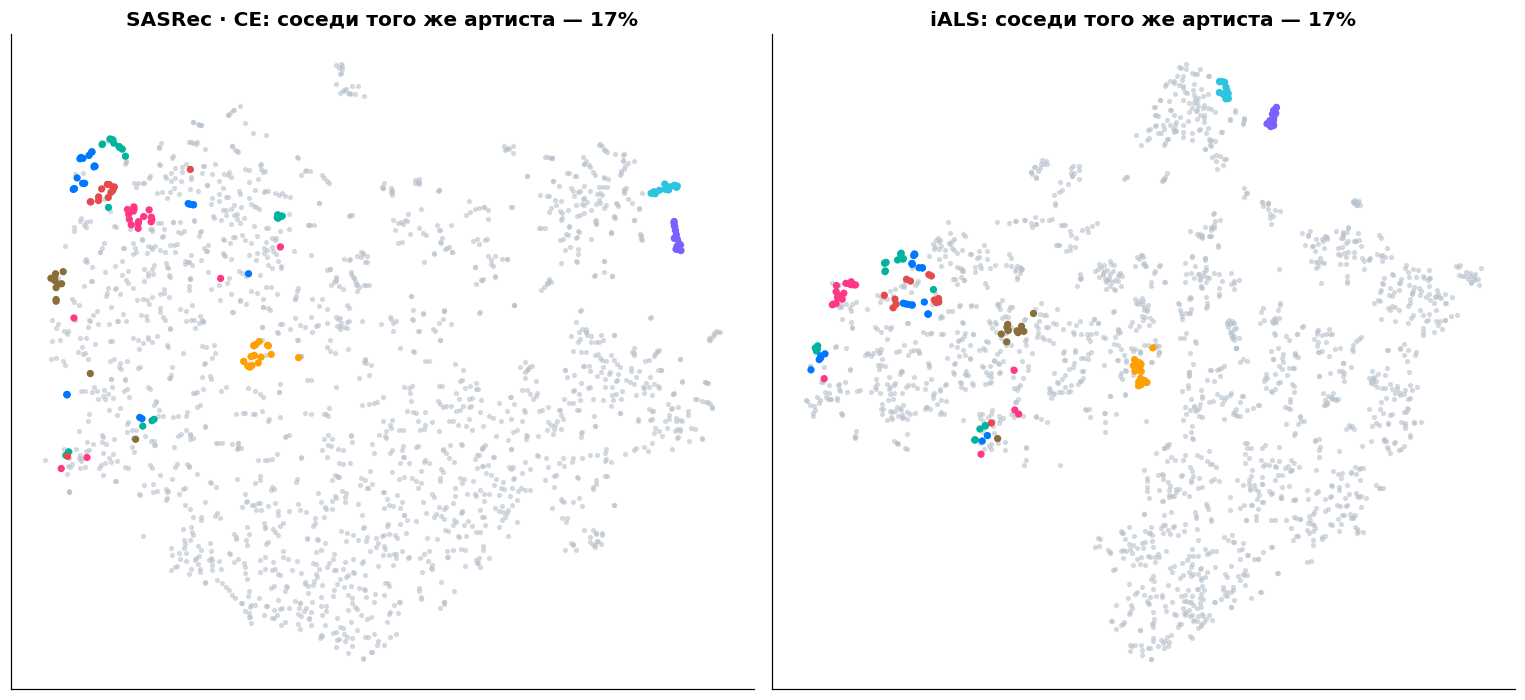

если бы соседи были случайными: 0.2%


In [35]:
from sklearn.manifold import TSNE

TOP_N = 2000
top_idx = np.arange(1, TOP_N + 1)                          # индекс = место по популярности
art = artist_of.reindex(catalog[top_idx - 1]).to_numpy()
top_art = list(pd.Series(art).value_counts().index[:len(PALETTE)])
colors = [PALETTE[top_art.index(a)] if a in top_art else GRAY for a in art]


def same_artist_share(E, k=10):
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    sim = E @ E.T
    np.fill_diagonal(sim, -np.inf)
    nn_idx = np.argpartition(-sim, k, axis=1)[:, :k]
    return (art[nn_idx] == art[:, None]).mean()


same = pd.Series(art).value_counts()
random_share = ((same * (same - 1)).sum()) / (TOP_N * (TOP_N - 1))    # если бы соседи были случайными

embs = {'SASRec · CE': sasrec_ce.item_emb.weight[top_idx].detach().float().cpu().numpy(),
        'iALS': V[top_idx]}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (name, E) in zip(axes, embs.items()):
    xy = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(E)
    is_top = np.array([c != GRAY for c in colors])
    ax.scatter(xy[~is_top, 0], xy[~is_top, 1], s=6, c=GRAY, alpha=0.5)
    ax.scatter(xy[is_top, 0], xy[is_top, 1], s=14, c=np.array(colors)[is_top])
    ax.set(title=f'{name}: соседи того же артиста — {same_artist_share(E):.0%}', xticks=[], yticks=[])
    ax.grid(False)
plt.tight_layout(); plt.show()
print(f'если бы соседи были случайными: {random_share:.1%}')

### Качество по длине истории

In [36]:
score_sas = make_score_fn(sasrec_ce, test_input_seqs, CFG['max_len'])
per_user = []
for name, fn in [('SASRec · CE', score_sas), ('Popular', score_popular), ('Соседи последнего айтема', score_last_item)]:
    _, pu = evaluate(fn, test_targets, test_input_seqs, ks=(10,), per_user=True)
    per_user.append(pu.query('filtered == False and target == "all"').assign(model=name))
per_user = pd.concat(per_user)
lens = pd.Series({u: len(s) for u, s in test_input_seqs.items()})
per_user['история'] = pd.cut(per_user.uid.map(lens), [0, 50, 200, 1000, 5000, np.inf],
                             labels=['≤50', '51–200', '201–1000', '1001–5000', '>5000'])
per_user.pivot_table(index='история', columns='model', values='NDCG@10', aggfunc='mean', observed=True).round(4)

model,Popular,SASRec · CE,Соседи последнего айтема
история,,,
≤50,0.0099,0.1409,0.1427
51–200,0.0207,0.1392,0.0933
201–1000,0.0158,0.1624,0.1029
1001–5000,0.0163,0.1249,0.0907
>5000,0.0198,0.1177,0.0834


### Перемешанная история
Перемешиваем последнее окно, сохраняя набор треков. Так проверяем вклад порядка.

In [37]:
rng = np.random.default_rng(SEED)
L = CFG['max_len']
shuffled_seqs = {u: np.concatenate([s[:-L], rng.permutation(s[-L:])]) for u, s in test_input_seqs.items()}   # только окно модели
res_shuffled = evaluate(make_score_fn(sasrec_ce, shuffled_seqs, CFG['max_len']), test_targets, test_input_seqs)
pd.DataFrame({
    'как есть': RESULTS['SASRec · CE'].set_index(['filtered', 'target'])['NDCG@10'],
    'перемешано': res_shuffled.set_index(['filtered', 'target'])['NDCG@10'],
}).round(4)

как есть  перемешано
filtered target                      
False    next      0.0827      0.0593
         all       0.1311      0.1147
True     next      0.0184      0.0069
         all       0.0236      0.0176

## 7. Сохранение модели

In [38]:
if LOAD:
    print('модели загружены из artifacts/, перезаписывать не нужно')
else:
    os.makedirs(ART_DIR, exist_ok=True)
    for name, model in [('ce', sasrec_ce), ('bce', sasrec_bce)]:
        torch.save({'state_dict': model.state_dict(), 'cfg': CFG, 'n_items': N_ITEMS}, CKPT[name])
    np.save(CATALOG_PATH, catalog)                                      # индекс i+1 -> item_id
    json.dump({'TRAIN_END': TRAIN_END, 'VAL_START': VAL_START, 'VAL_END': VAL_END, 'TEST_START': TEST_START},
              open(f'{ART_DIR}/split.json', 'w'))
    curves = dict(val_ce=val_ce, val_bce=val_bce, losses_ce=losses_ce, losses_bce=losses_bce,
                  val_causal=val_causal, val_leak=val_leak, losses_causal=losses_causal, losses_leak=losses_leak)
    json.dump({k: [round(float(x), 5) for x in v] for k, v in curves.items()}, open(HIST_PATH, 'w'))
sorted(os.listdir(ART_DIR))


['catalog_item_ids.npy',
 'history.json',
 'sasrec_bce.pt',
 'sasrec_ce.pt',
 'split.json']

## Выводы
- Повторы важны: **83%** органических прослушиваний теста.
- SASRec CE лучше BCE: **0.1311 > 0.0562** по NDCG@10.
- При перемешивании истории NDCG@10 падает **0.1311 → 0.1147**: порядок учитывается.
- С официальным бенчмарком значения напрямую не сравниваем: разные таргеты и каталог.